<a href="https://colab.research.google.com/github/PallaviChikkala/Speech-fluency-evaluation-for-automated-interview-simulation/blob/main/GRU_Speech_Interview_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ============================================================
# 1. REPRODUCIBILITY & SAFE DRIVE MOUNT
# ============================================================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
warnings.filterwarnings("ignore")

# Safe mount check
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")
else:
    print("Google Drive is already mounted.")

PROJECT_PATH = "/content/drive/MyDrive/Speech_Interview_Evaluation"
DATASET_PATH = os.path.join(PROJECT_PATH, "dataset")
WAV_PATH = os.path.join(DATASET_PATH, "audio_wav")
LABEL_PATH = os.path.join(DATASET_PATH, "labels")
MODEL_PATH = os.path.join(PROJECT_PATH, "models")
RESULT_PATH = os.path.join(PROJECT_PATH, "results")

os.makedirs(MODEL_PATH, exist_ok=True)
os.makedirs(RESULT_PATH, exist_ok=True)

# Verify Excel file path dynamically
ratings_file = os.path.join(LABEL_PATH, "ICNALE GRA 2_1.xlsx")

if not os.path.isfile(ratings_file):
    files_in_label_path = os.listdir(LABEL_PATH) if os.path.exists(LABEL_PATH) else []
    excel_files = [f for f in files_in_label_path if f.endswith(".xlsx")]
    if excel_files:
        ratings_file = os.path.join(LABEL_PATH, excel_files[0])
        print(f"Using located Excel file: {ratings_file}")
    else:
        raise FileNotFoundError(f"Could not locate ratings Excel file inside {LABEL_PATH}")
else:
    print(f"Found ratings file: {ratings_file}")

Mounted at /content/drive
Found ratings file: /content/drive/MyDrive/Speech_Interview_Evaluation/dataset/labels/ICNALE GRA 2_1.xlsx


In [ ]:
# ============================================================
# 2. LOAD LABELS & EXTRACT COMPREHENSIVE FEATURES
# ============================================================
ratings_raw = pd.read_excel(ratings_file, sheet_name="3_Rating", header=None)

# Dynamic header detection
header_row = None
for i in range(len(ratings_raw)):
    row_vals = ratings_raw.iloc[i].astype(str).str.strip().tolist()
    if "Sample Code" in row_vals:
        header_row = i
        break

ratings = pd.read_excel(ratings_file, sheet_name="3_Rating", header=header_row)
ratings = ratings.dropna(axis=0, how="all").dropna(axis=1, how="all")
ratings.columns = ratings.columns.astype(str).str.strip()

speech_ratings = ratings[
    ratings["Sample Code"].astype(str).str.startswith("Speech_")
].copy()

speech_ratings = speech_ratings[
    speech_ratings["Fluency (Language)"].between(0, 10)
].copy()

labels_df = (
    speech_ratings.groupby("Sample Code")["Fluency (Language)"]
    .mean()
    .reset_index()
    .rename(columns={"Fluency (Language)": "Fluency_Score"})
    .sort_values("Sample Code")
    .reset_index(drop=True)
)

TARGET_SR = 16000
N_MFCC = 20

def extract_comprehensive_features(wav_path):
    y, sr = librosa.load(wav_path, sr=TARGET_SR, mono=True)

    # Spectral Dynamics
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
    delta1 = librosa.feature.delta(mfcc)
    delta2 = librosa.feature.delta(mfcc, order=2)

    # Prosody & Speech Rate Cues
    rms = librosa.feature.rms(y=y)
    zcr = librosa.feature.zero_crossing_rate(y=y)

    rms = librosa.util.fix_length(rms, size=mfcc.shape[1], axis=1)
    zcr = librosa.util.fix_length(zcr, size=mfcc.shape[1], axis=1)

    combined = np.vstack([mfcc, delta1, delta2, rms, zcr]).T  # 62 dimensions
    return combined

feature_list, sample_id_list = [], []
for idx, row in labels_df.iterrows():
    s_id = row["Sample Code"]
    w_path = os.path.join(WAV_PATH, f"{s_id}.wav")
    if os.path.isfile(w_path):
        feats = extract_comprehensive_features(w_path)
        feature_list.append(feats)
        sample_id_list.append(s_id)

    if (idx + 1) % 20 == 0 or (idx + 1) == len(labels_df):
        print(f"Processed {idx + 1}/{len(labels_df)} audio files...")

TARGET_FRAMES = 2900
N_FEATURES = feature_list[0].shape[1]

X_all = np.zeros((len(feature_list), TARGET_FRAMES, N_FEATURES), dtype=np.float32)
for i, feats in enumerate(feature_list):
    nf = min(feats.shape[0], TARGET_FRAMES)
    X_all[i, :nf, :] = feats[:nf]

label_lookup = dict(zip(labels_df["Sample Code"], labels_df["Fluency_Score"]))
y_all = np.array([label_lookup[s_id] for s_id in sample_id_list], dtype=np.float32)

print("\nFeature extraction complete!")
print("X_all shape:", X_all.shape)
print("y_all shape:", y_all.shape)

Processed 20/140 audio files...
Processed 40/140 audio files...
Processed 60/140 audio files...
Processed 80/140 audio files...
Processed 100/140 audio files...
Processed 120/140 audio files...
Processed 140/140 audio files...

Feature extraction complete!
X_all shape: (140, 2900, 62)
y_all shape: (140,)


In [ ]:
# ============================================================
# 3. STRATIFIED SPLIT & TRAIN-ONLY NORMALIZATION
# ============================================================
score_bins = pd.qcut(y_all, q=5, labels=False, duplicates="drop")

X_train, X_temp, y_train, y_temp, ids_train, ids_temp, b_train, b_temp = train_test_split(
    X_all, y_all, np.array(sample_id_list), score_bins, test_size=0.30, random_state=SEED, stratify=score_bins
)
X_val, X_test, y_val, y_test, ids_val, ids_test = train_test_split(
    X_temp, y_temp, ids_temp, test_size=0.50, random_state=SEED, stratify=b_temp
)

# Compute normalization statistics strictly on training data
train_mean = X_train.mean(axis=(0, 1), keepdims=True)
train_std = X_train.std(axis=(0, 1), keepdims=True)
train_std = np.where(train_std < 1e-8, 1.0, train_std)

X_train_norm = (X_train - train_mean) / train_std
X_val_norm = (X_val - train_mean) / train_std
X_test_norm = (X_test - train_mean) / train_std

BATCH_SIZE = 8
train_ds = tf.data.Dataset.from_tensor_slices((X_train_norm, y_train)).shuffle(len(X_train_norm), seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((X_val_norm, y_val)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((X_test_norm, y_test)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Train shape:", X_train_norm.shape)
print("Val shape  :", X_val_norm.shape)
print("Test shape :", X_test_norm.shape)

Train shape: (98, 2900, 62)
Val shape  : (21, 2900, 62)
Test shape : (21, 2900, 62)


In [ ]:
# ============================================================
# 4. CCC + MSE LOSS & BiGRU-ATTENTION ARCHITECTURE
# ============================================================
def ccc_mse_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    mean_true = tf.reduce_mean(y_true)
    mean_pred = tf.reduce_mean(y_pred)

    var_true = tf.math.reduce_variance(y_true)
    var_pred = tf.math.reduce_variance(y_pred)

    covar = tf.reduce_mean((y_true - mean_true) * (y_pred - mean_pred))
    ccc = (2.0 * covar) / (var_true + var_pred + tf.square(mean_true - mean_pred) + 1e-8)
    mse = tf.reduce_mean(tf.square(y_true - y_pred))

    return (1.0 - ccc) + 0.5 * mse

class TemporalAttention(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(name="att_weight", shape=(input_shape[-1], 1), initializer="glorot_uniform")
        self.b = self.add_weight(name="att_bias", shape=(1,), initializer="zeros")
        super().build(input_shape)

    def call(self, inputs):
        e = tf.tanh(tf.matmul(inputs, self.W) + self.b)
        a = tf.nn.softmax(e, axis=1)
        return tf.reduce_sum(inputs * a, axis=1)

inputs = tf.keras.Input(shape=(TARGET_FRAMES, N_FEATURES), name="speech_features")

# Temporal 1D Convolution Downsampling
x = tf.keras.layers.Conv1D(64, kernel_size=5, strides=2, padding="same", activation="gelu")(inputs)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Conv1D(64, kernel_size=3, strides=2, padding="same", activation="gelu")(x)
x = tf.keras.layers.BatchNormalization()(x)

# Bidirectional GRU for Sequential Speech Nuances
x = tf.keras.layers.Bidirectional(tf.keras.layers.GRU(64, return_sequences=True, dropout=0.2))(x)
x = tf.keras.layers.Bidirectional(tf.keras.layers.GRU(32, return_sequences=True, dropout=0.2))(x)

# Learnable Attention Pooling across time
x = TemporalAttention()(x)

# Regression Output Head
x = tf.keras.layers.Dense(32, activation="gelu")(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(1, activation="linear", name="fluency_score")(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs, name="Speech_Fluency_BiGRU_Attn")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
    loss=ccc_mse_loss,
    metrics=["mae"]
)

model.summary()

Model: "Speech_Fluency_BiGRU_Attn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ speech_features (InputLayer)    │ (None, 2900, 62)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 1450, 64)       │        19,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1450, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 725, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 725, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 725, 128)       │        49,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 725, 64)        │        31,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_attention              │ (None, 64)             │            65 │
│ (TemporalAttention)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fluency_score (Dense)           │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 115,970 (453.01 KB)

 Trainable params: 115,714 (452.01 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 754ms/step - loss: 14.3122 - mae: 4.9667
Epoch 1: val_loss improved from None to 16.09899, saving model to /content/drive/MyDrive/Speech_Interview_Evaluation/models/fluency_model_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Speech_Interview_Evaluation/models/fluency_model_best.keras
13/13 ━━━━━━━━━━━━━━━━━━━━ 21s 904ms/step - loss: 13.5788 - mae: 4.7860 - val_loss: 16.0990 - val_mae: 5.2450 - learning_rate: 5.0000e-04
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 731ms/step - loss: 10.4660 - mae: 4.0232
Epoch 2: val_loss did not improve from 16.09899
13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 761ms/step - loss: 10.3318 - mae: 3.9995 - val_loss: 16.7119 - val_mae: 5.2343 - learning_rate: 5.0000e-04
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 790ms/step - loss: 6.0028 - mae: 2.6760
Epoch 3: val_loss improved from 16.09899 to 13.51938, saving model to /content/drive/MyDrive/Speech_Interview_Evaluation/models/fluency_model_best.keras

Epoch 3: f

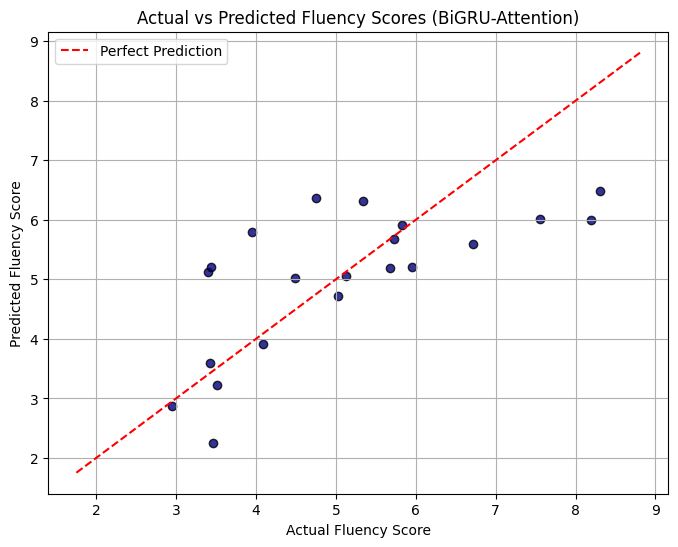

In [ ]:
# ============================================================
# 5. TRAINING & EVALUATION
# ============================================================
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(MODEL_PATH, "fluency_model_best.keras"),
        monitor="val_loss", save_best_only=True, verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=60,
    callbacks=callbacks,
    verbose=1
)

# Predict on Test Set
y_pred = model.predict(X_test_norm).flatten()

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\nFinal Test Metrics:\nMAE: {mae:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f}")

# Plot Actual vs Predicted
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.8, color="navy", edgecolors="k")
min_val = min(y_test.min(), y_pred.min()) - 0.5
max_val = max(y_test.max(), y_pred.max()) + 0.5
plt.plot([min_val, max_val], [min_val, max_val], "r--", label="Perfect Prediction")
plt.xlabel("Actual Fluency Score")
plt.ylabel("Predicted Fluency Score")
plt.title("Actual vs Predicted Fluency Scores (BiGRU-Attention)")
plt.legend()
plt.grid(True)
plt.show()

Discretized Classification Accuracy: 61.90%

Classification Report:
              precision    recall  f1-score   support

 Low Fluency       0.00      0.00      0.00         4
 Mid Fluency       1.00      0.56      0.71         9
High Fluency       0.50      1.00      0.67         8

    accuracy                           0.62        21
   macro avg       0.50      0.52      0.46        21
weighted avg       0.62      0.62      0.56        21



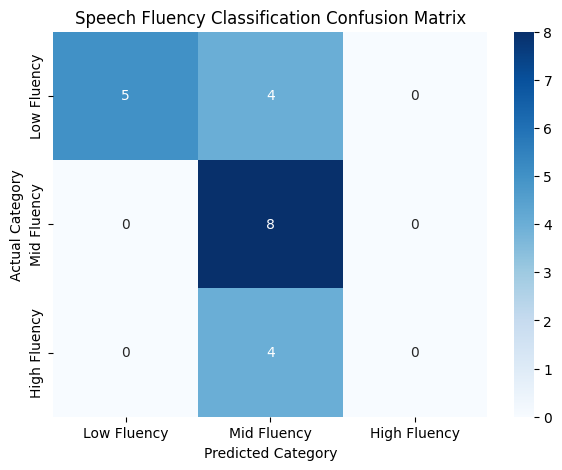

In [ ]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ============================================================
# 6. DISCRETIZATION FOR CLASSIFICATION METRICS & CONFUSION MATRIX
# ============================================================

# Define Fluency Score Categories/Bands
# Band 1: Low Fluency  (0.0 to 4.5)
# Band 2: Mid Fluency  (4.5 to 6.5)
# Band 3: High Fluency (6.5 to 10.0)
bins = [0.0, 4.5, 6.5, 10.0]
category_labels = ["Low Fluency", "Mid Fluency", "High Fluency"]

# Convert continuous actual & predicted values into discrete categories
y_test_cat = pd.cut(y_test, bins=bins, labels=category_labels, include_lowest=True)
y_pred_cat = pd.cut(y_pred, bins=bins, labels=category_labels, include_lowest=True)

# 1. Compute Classification Accuracy
acc = accuracy_score(y_test_cat, y_pred_cat)
print("==================================================")
print(f"Discretized Classification Accuracy: {acc * 100:.2f}%")
print("==================================================\n")

# 2. Detailed Classification Report (Precision, Recall, F1)
print("Classification Report:")
print(classification_report(y_test_cat, y_pred_cat, target_names=category_labels))

# 3. Compute Confusion Matrix
cm = confusion_matrix(y_test_cat, y_pred_cat, labels=category_labels)

# 4. Plot Confusion Matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=category_labels,
    yticklabels=category_labels
)
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Speech Fluency Classification Confusion Matrix")
plt.show()x